# Quantitative Portfolio Risk & Optimisation Analysis

This project analyses how portfolio construction affects risk-adjusted returns using historical market data. It compares a manually selected portfolio with the S&P 500, evaluates diversification and risk metrics, and uses Monte Carlo simulation to explore alternative portfolio allocations.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

## Portfolio Construction 

The portfolio combines broad US and emerging-market equity exposure with selected individual equities, US government bonds and gold.

The initial allocation was selected before analysing historical performance. SPY forms the core US equity exposure, while MSFT, JPM and CAT represent individual-stock overweights. VWO provides emerging-market diversification, while IEF and GLD introduce fixed-income and alternative-asset exposure.

The initial weights are:
SPY 30% | MSFT 12.5% | JPM 10% | CAT 7.5% | VWO 10% | GLD 10% | IEF 20%

In [2]:
tickers = ["SPY", "MSFT", "JPM", "CAT", "VWO", "GLD", "IEF"]
weights = np.array([0.30, 0.125, 0.10, 0.075, 0.10, 0.10, 0.20])

weights.sum()

np.float64(1.0)

# Historical Market Data

Historical adjusted closing prices are downloaded using `yfinance`. The analysis uses approximately ten years of daily market data to capture performance across a range of market and economic conditions. Adjusted closing prices account for corporate actions such as dividends and stock splits, providing a more accurate representation of historical investor returns.

In [3]:
start_date = "2016-01-01"
end_date = "2026-09-01"

price_download = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False,
    threads=False
)

if price_download.empty:
    raise RuntimeError("No market data was downloaded. Try again after a short wait.")

prices = price_download["Close"]

In [4]:
risk_free_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"

## Data cleansing

It is important that there are no missing or null values within the data that can skew any calculations.

In [5]:
prices = prices[tickers]

In [6]:
prices.head()
prices.isna().sum()

Ticker
SPY     0
MSFT    0
JPM     0
CAT     0
VWO     0
GLD     0
IEF     0
dtype: int64

In [7]:
returns = prices.pct_change().dropna()
returns = returns[tickers]

In [8]:
portfolio_returns = (returns * weights).sum(axis=1)
portfolio_returns.tail()
annualised_mean_returns = portfolio_returns.mean() * 252

## Geometric annualised return (CAGR)

This metric measures the portfolio's realised annualised return over the historical period, accounting for compounding.

In [9]:
total_growth = (1 + portfolio_returns).prod()
total_growth

np.float64(4.615169847543394)

In [10]:
days = (portfolio_returns.index[-1] - portfolio_returns.index[0]).days
years = days / 365.25

In [11]:
cagr = total_growth ** (1 / years) - 1
cagr

np.float64(0.1543768551045792)

## Annualised Volatility

Volatility measures the variability of the portfolio's return and is used as a measure of investment risk.

In [12]:
daily_volatility = portfolio_returns.std()
annualised_volatility = daily_volatility * np.sqrt(252)
annualised_volatility

np.float64(0.13310704638760573)

## Sharpe Ratio

The Sharpe ratio measures the portfolio's risk-adjusted performance by comparing its return above the risk-free rate with its volatility.

A higher Sharpe ratio indicates greater excess return per unit of risk.

$$
\text{Sharpe Ratio} = \frac{R_p - R_f}{\sigma_p}
$$

where:

- \(R_p\) = annualised mean portfolio return
- \(R_f\) = annual risk-free rate
- \(\sigma_p\) = annualised portfolio volatility



In [13]:
annualised_mean_portfolio_return = portfolio_returns.mean() * 252
annualised_mean_portfolio_return

np.float64(0.15276542625313286)

### Risk-Free Rate

The 3-month US Treasury bill rate is used as a proxy for the risk-free rate due to its low credit and duration risk. Historical rates are sourced from the Federal Reserve Economic Data (FRED) database and aligned with the portfolio's analysis period.

Daily portfolio excess returns are calculated using the corresponding risk-free rate, ensuring that the risk-free benchmark reflects changes in interest rates over the historical period rather than assuming a single constant rate.

In [14]:
risk_free_data = pd.read_csv(risk_free_url)
risk_free_data["observation_date"] = pd.to_datetime(risk_free_data["observation_date"])
risk_free_data["observation_date"] >= "2016-01-05"

risk_free_period = risk_free_data[
    (risk_free_data["observation_date"] >= "2016-01-05") & 
    (risk_free_data["observation_date"] <= "2026-08-31")
].copy()

In [15]:
risk_free_period["DTB3"] = risk_free_period["DTB3"].ffill()
risk_free_period["annual_rfr"] = risk_free_period["DTB3"] / 100
risk_free_period[["DTB3", "annual_rfr"]].head()

,DTB3,annual_rfr
16176,0.20,0.0020
16177,0.21,0.0021
16178,0.20,0.0020
16179,0.20,0.0020
16180,0.21,0.0021


In [16]:
risk_free_period["daily_rfr"] = (1 + risk_free_period["annual_rfr"])**(1 / 252) - 1

risk_free_period.head()

,observation_date,DTB3,annual_rfr,daily_rfr
16176,2016-01-05,0.20,0.0020,0.000008
16177,2016-01-06,0.21,0.0021,0.000008
16178,2016-01-07,0.20,0.0020,0.000008
16179,2016-01-08,0.20,0.0020,0.000008
16180,2016-01-11,0.21,0.0021,0.000008


In [17]:
risk_free_period = risk_free_period.set_index("observation_date")

aligned_daily_rfr = risk_free_period["daily_rfr"].reindex(portfolio_returns.index)

daily_excess_returns = portfolio_returns - aligned_daily_rfr
annualised_excess_return = daily_excess_returns.mean() * 252
annualised_excess_return

np.float64(0.13051879323997237)

In [18]:
sharpe_ratio = (annualised_excess_return / annualised_volatility)
sharpe_ratio

np.float64(0.9805551004407654)

## Maximum Drawdown

Maximum drawdown measures the largest percentage decline in the portfolio's value from a historical peak to a subsequent trough, providing a measure of downside risk beyond overall return volatility.

In [19]:
cumulative_value = (1 + portfolio_returns).cumprod()
running_peak = cumulative_value.cummax()

drawdown = (cumulative_value / running_peak) - 1
drawdown.head()

max_drawdown = drawdown.min()
max_drawdown_date = drawdown.idxmin()
max_drawdown_date

Timestamp('2020-03-23 00:00:00')

The portfolio's maximum drawdown was approximately **-23.3%**, reaching its deepest point on **23 March 2020** during the COVID-19 market crash.

## Benchmark Comparison

This manually constructed portfolio is compared with SPY, an ETF tracking the S&P 500, to assess whether the portfolio's diversification and active security overweights improved historical risk-adjusted performance relative to a passive US equity benchmark.

In [20]:
spy_returns = returns["SPY"]

spy_total_growth = (1 + spy_returns).prod()
spy_cagr = spy_total_growth ** (1 / years) - 1

spy_daily_volatility = spy_returns.std()
spy_annualised_volatility = spy_daily_volatility * np.sqrt(252)

spy_daily_excess_returns = spy_returns - aligned_daily_rfr
spy_annualised_excess_returns = spy_daily_excess_returns.mean() * 252

spy_sharpe_ratio = spy_annualised_excess_returns / spy_annualised_volatility

spy_cumulative_value = (1 + spy_returns).cumprod()
spy_running_peak = spy_cumulative_value.cummax()
spy_drawdown = (spy_cumulative_value / spy_running_peak) - 1
spy_max_drawdown = spy_drawdown.min()
spy_max_drawdown_date = spy_drawdown.idxmin()


In [21]:
summary = pd.DataFrame({
    "Portfolio": [cagr, annualised_volatility, sharpe_ratio, max_drawdown],
    "SPY": [spy_cagr, spy_annualised_volatility, spy_sharpe_ratio, spy_max_drawdown]
})
summary.index = [
    "CAGR",
    "Annualised Volatility",
    "Sharpe Ratio",
    "Maximum Drawdown"
]
summary

,Portfolio,SPY
CAGR,0.153016,0.150927
Annualised Volatility,0.133107,0.177572
Sharpe Ratio,0.980555,0.763762
Maximum Drawdown,-0.232786,-0.337173


## Correlation Analysis

The correlation matrix measures the degree to which the returns of different assets move together. Lower or negative correlations between assets can reduce overall portfolio risk through diversification.

In [22]:
correlation_matrix = returns.corr()
correlation_matrix.index.name = None
correlation_matrix.columns.name = None

### Correlation Heatmap

The heatmap provides a visual representation of the relationships between asset returns. Lower correlations indicate greater potential diversification benefits when assets are combined within a portfolio.

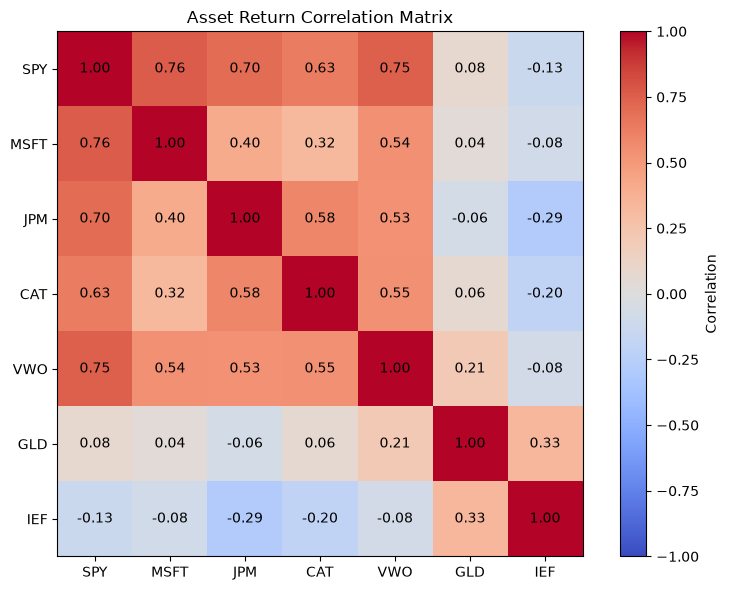

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(tickers)))
ax.set_yticks(range(len(tickers)))
ax.set_xticklabels(tickers)
ax.set_yticklabels(tickers)

for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(heatmap, ax=ax, label="Correlation")
ax.set_title("Asset Return Correlation Matrix")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
cov_matrix_daily = returns.cov() 
cov_matrix_annualised = cov_matrix_daily * 252

In [25]:
portfolio_variance = weights.T @ cov_matrix_annualised @ weights
portfolio_variance

portfolio_volatility_matrix = np.sqrt(portfolio_variance)
portfolio_volatility_matrix

np.float64(0.13310704638760573)

## Portfolio Optimisation

To investigate whether alternative asset allocations could have improved the portfolio's historical risk-return characteristics, a Monte Carlo simulation is used to generate 10,000 portfolios with randomly assigned long-only weights that sum to 100%.

Each simulated portfolio is evaluated using its expected annualised return, annualised volatility and Sharpe ratio. The simulation is then used to identify the portfolio with the highest Sharpe ratio and the portfolio with the lowest volatility.

Historical mean returns and the annualised covariance matrix are used as inputs. Therefore, the results represent optimisation based on historical data rather than predictions of future performance.

### Expected Returns

Historical mean daily returns are annualised and used as estimates of expected returns for the portfolio simulation.

In [26]:
mean_returns = returns.mean() * 252
manual_expected_return = mean_returns @ weights
spy_expected_return = mean_returns["SPY"]

### Monte Carlo Simulation

To explore alternative portfolio allocations, 10,000 long-only portfolios are generated with randomly assigned weights that sum to 100%. Each portfolio's expected return, volatility and Sharpe ratio are calculated using the historical expected-return estimates and covariance matrix.


In [27]:
random_weights = np.random.random(len(tickers))
random_weights = random_weights / random_weights.sum()

random_portfolio_return = random_weights @ mean_returns
random_portfolio_volatility = np.sqrt(random_weights.T @ cov_matrix_annualised @ random_weights)

average_annual_rfr = risk_free_period["annual_rfr"].mean()
random_portfolio_sharpe_ratio = (random_portfolio_return - average_annual_rfr) / random_portfolio_volatility
random_portfolio_sharpe_ratio

np.float64(1.0982140212630955)

In [28]:
np.random.seed(100)
num_portfolios = 10000

portfolio_returns_sim = []
portfolio_volatilities_sim = []
portfolio_sharpe_ratios_sim = []
portfolio_weights_sim = []

for _ in range(num_portfolios):
    random_weights = np.random.random(len(tickers))
    random_weights = random_weights / random_weights.sum()
    
    random_portfolio_return = random_weights @ mean_returns
    
    random_portfolio_volatility = np.sqrt(random_weights.T @ cov_matrix_annualised @ random_weights)
    
    random_portfolio_sharpe_ratio = (random_portfolio_return - average_annual_rfr) / random_portfolio_volatility
    
    portfolio_returns_sim.append(random_portfolio_return)
    portfolio_volatilities_sim.append(random_portfolio_volatility)
    portfolio_sharpe_ratios_sim.append(random_portfolio_sharpe_ratio)
    portfolio_weights_sim.append(random_weights)

In [29]:
sim_results = pd.DataFrame({
    "Return": portfolio_returns_sim,
    "Volatility": portfolio_volatilities_sim,
    "Sharpe": portfolio_sharpe_ratios_sim
})

In [30]:
max_sharpe_index = sim_results["Sharpe"].idxmax()
max_sharpe_portfolio = sim_results.loc[max_sharpe_index]

max_sharpe_weights = portfolio_weights_sim[max_sharpe_index]
max_sharpe_portfolio



Return        0.203145
Volatility    0.145154
Sharpe        1.243064
Name: 9394, dtype: float64

In [31]:
min_volatility_index = sim_results["Volatility"].idxmin()
min_volatility_portfolio = sim_results.loc[min_volatility_index]

min_volatility_weights = portfolio_weights_sim[min_volatility_index]
min_volatility_weights
min_volatility_portfolio

Return        0.096679
Volatility    0.080212
Sharpe        0.922161
Name: 5281, dtype: float64

### Simulated Portfolio Opportunity Set

The simulated portfolios are plotted according to their annualised expected return and volatility. Each point represents a different asset allocation, with the colour scale representing its Sharpe ratio. The maximum-Sharpe and minimum-volatility portfolios are highlighted for comparison.

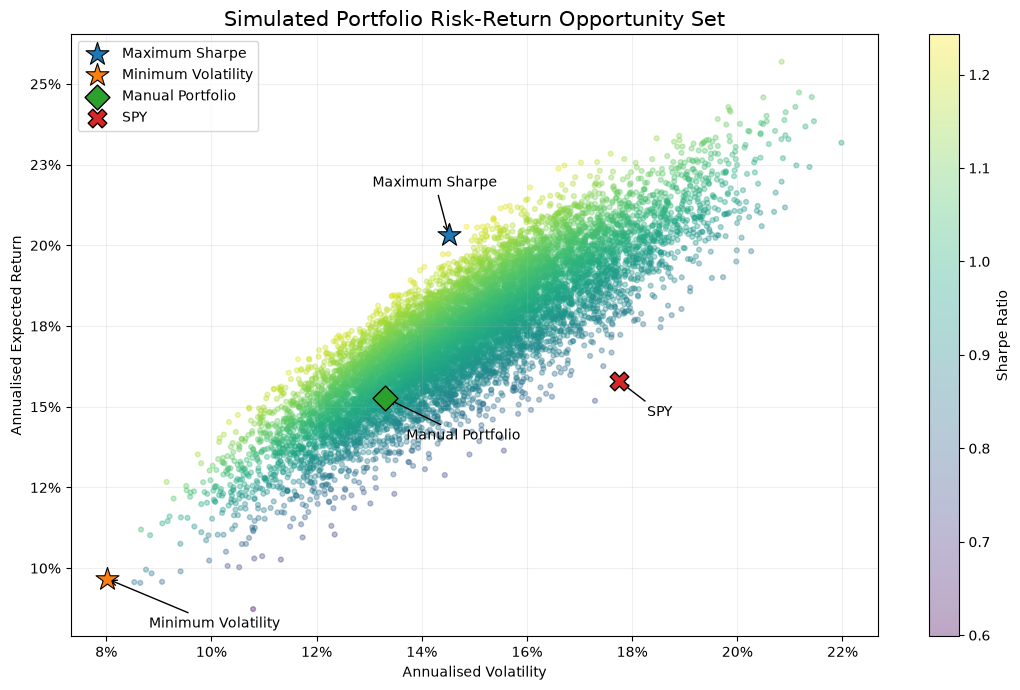

In [32]:
fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(
    sim_results["Volatility"],
    sim_results["Return"],
    c=sim_results["Sharpe"],
    alpha=0.35,
    s=12
)

ax.scatter(
    max_sharpe_portfolio["Volatility"],
    max_sharpe_portfolio["Return"],
    marker="*",
    s=300,
    edgecolors="black",
    linewidths=0.8,
    label="Maximum Sharpe",
    zorder=5
)

ax.scatter(
    min_volatility_portfolio["Volatility"],
    min_volatility_portfolio["Return"],
    marker="*",
    s=300,
    edgecolors="black",
    linewidths=0.8,
    label="Minimum Volatility",
    zorder=5
)

ax.scatter(
    portfolio_volatility_matrix,
    manual_expected_return,
    marker="D",
    s=160,
    edgecolors="black",
    linewidths=1,
    label="Manual Portfolio",
    zorder=6
)

ax.scatter(
    spy_annualised_volatility,
    spy_expected_return,
    marker="X",
    s=180,
    edgecolors="black",
    linewidths=1,
    label="SPY",
    zorder=6
)

ax.annotate(
    "Manual Portfolio",
    xy=(portfolio_volatility_matrix, manual_expected_return),
    xytext=(15, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

ax.annotate(
    "SPY",
    xy=(spy_annualised_volatility, spy_expected_return),
    xytext=(20, -25),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

ax.annotate(
    "Maximum Sharpe",
    xy=(
        max_sharpe_portfolio["Volatility"],
        max_sharpe_portfolio["Return"]
    ),
    xytext=(-10, 35),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

ax.annotate(
    "Minimum Volatility",
    xy=(
        min_volatility_portfolio["Volatility"],
        min_volatility_portfolio["Return"]
    ),
    xytext=(30, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

ax.set_title(
    "Simulated Portfolio Risk-Return Opportunity Set",
    fontsize=15
)
ax.set_xlabel("Annualised Volatility")
ax.set_ylabel("Annualised Expected Return")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

fig.colorbar(
    scatter,
    ax=ax,
    label="Sharpe Ratio"
)

ax.legend(loc="upper left")
ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "risk_return_opportunity_set.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
manual_expected_return = mean_returns @ weights
manual_expected_return

spy_expected_return = mean_returns["SPY"]

### Historical Backtest of Simulated Portfolios

The maximum-Sharpe and minimum-volatility allocations identified by the Monte Carlo simulation are applied to the historical daily return data. Their realised CAGR, volatility, Sharpe ratio and maximum drawdown are then compared with the manual portfolio and SPY.

In [34]:
def calculate_performance_metrics(return_series, risk_free_series):
    total_growth = (1 + return_series).prod()
    days = (return_series.index[-1] - return_series.index[0]).days
    years = days / 365.25
    cagr = total_growth ** (1 / years) - 1
    
    annualised_volatility = return_series.std() * np.sqrt(252)
    
    aligned_rfr = risk_free_series.reindex(return_series.index)
    excess_returns = return_series - aligned_rfr
    annualised_excess_return = excess_returns.mean() * 252
    sharpe_ratio = annualised_excess_return / annualised_volatility
    
    cumulative_value = (1 + return_series).cumprod() 
    running_peak = cumulative_value.cummax()
    drawdown = (cumulative_value / running_peak) - 1
    max_drawdown = drawdown.min()
    max_drawdown_date = drawdown.idxmin()

    return {
        "CAGR": cagr,
        "Annualised Volatility": annualised_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": max_drawdown,
        "Maximum Drawdown Date": max_drawdown_date
    }

In [35]:
max_sharpe_returns = (returns * max_sharpe_weights).sum(axis=1)

max_sharpe_metrics = calculate_performance_metrics(
    max_sharpe_returns,
    aligned_daily_rfr
)

max_sharpe_metrics

{'CAGR': np.float64(0.21184557878442),
 'Annualised Volatility': np.float64(0.1451536079825333),
 'Sharpe Ratio': np.float64(1.2462559782938933),
 'Maximum Drawdown': np.float64(-0.2004427190662582),
 'Maximum Drawdown Date': Timestamp('2022-09-27 00:00:00')}

In [36]:
min_volatility_returns = (returns * min_volatility_weights).sum(axis=1)

min_volatility_metrics = calculate_performance_metrics(
    min_volatility_returns,
    aligned_daily_rfr
)

min_volatility_metrics

{'CAGR': np.float64(0.0977378771927706),
 'Annualised Volatility': np.float64(0.08021231344914814),
 'Sharpe Ratio': np.float64(0.9279366269160109),
 'Maximum Drawdown': np.float64(-0.19099079817681142),
 'Maximum Drawdown Date': Timestamp('2022-09-27 00:00:00')}

## Historical Performance Comparison

The manually constructed portfolio, SPY benchmark and two portfolios identified through the Monte Carlo simulation are compared using realised historical performance metrics.

In [37]:
comparison = pd.DataFrame({
    "Manual Portfolio": calculate_performance_metrics(
        portfolio_returns,
        aligned_daily_rfr
    ),
    "SPY": calculate_performance_metrics(
        spy_returns,
        aligned_daily_rfr
    ),
    "Maximum Sharpe": calculate_performance_metrics(
        max_sharpe_returns,
        aligned_daily_rfr
    ),
    "Minimum Volatility": calculate_performance_metrics(
        min_volatility_returns,
        aligned_daily_rfr
    )
})

comparison

,Manual Portfolio,SPY,Maximum Sharpe,Minimum Volatility
CAGR,0.154377,0.152268,0.211846,0.097738
Annualised Volatility,0.133107,0.177572,0.145154,0.080212
Sharpe Ratio,0.980555,0.763762,1.246256,0.927937
Maximum Drawdown,-0.232786,-0.337173,-0.200443,-0.190991
Maximum Drawdown Date,2020-03-23 00:00:00,2020-03-23 00:00:00,2022-09-27 00:00:00,2022-09-27 00:00:00


## Out-of-Sample Analysis

To reduce the risk of overfitting, the historical data is divided into separate training and testing periods. Portfolio allocations are selected using only data from the training period and are then evaluated on unseen test-period data.

- Training period: 2016–2021
- Testing period: 2022–2026

In [38]:
train_returns = returns.loc["2016-01-01":"2021-12-31"]
test_returns = returns.loc["2022-01-01":"2026-08-31"]
print("Training period:", train_returns.index.min(), "to", train_returns.index.max())
print("Testing period:", test_returns.index.min(), "to", test_returns.index.max())

Training period: 2016-01-05 00:00:00 to 2021-12-31 00:00:00
Testing period: 2022-01-03 00:00:00 to 2026-08-31 00:00:00


In [39]:
train_mean_returns = train_returns.mean() * 252
train_cov_matrix = train_returns.cov() * 252
train_rfr = risk_free_period.loc[
    "2016-01-01":"2021-12-31", "annual_rfr"
].mean()

### Training-Period Monte Carlo Simulation

Using only the training-period expected returns and covariance matrix, 10,000 long-only portfolios are simulated. The maximum-Sharpe and minimum-volatility allocations identified here are then carried forward unchanged into the test period.

In [40]:
np.random.seed(100)

train_portfolio_returns_sim = []
train_portfolio_volatilities_sim = []
train_portfolio_sharpe_ratios_sim = []
train_portfolio_weights_sim = []

for _ in range(num_portfolios):
    random_weights = np.random.random(len(tickers))
    random_weights = random_weights / random_weights.sum()

    random_portfolio_return = random_weights @ train_mean_returns

    random_portfolio_volatility = np.sqrt(
        random_weights.T @ train_cov_matrix @ random_weights
    )

    random_portfolio_sharpe = (
        random_portfolio_return - train_rfr
    ) / random_portfolio_volatility

    train_portfolio_returns_sim.append(random_portfolio_return)
    train_portfolio_volatilities_sim.append(random_portfolio_volatility)
    train_portfolio_sharpe_ratios_sim.append(random_portfolio_sharpe)
    train_portfolio_weights_sim.append(random_weights)

In [41]:
train_sim_results = pd.DataFrame({
    "Return": train_portfolio_returns_sim,
    "Volatility": train_portfolio_volatilities_sim,
    "Sharpe": train_portfolio_sharpe_ratios_sim
})

train_max_sharpe_index = train_sim_results["Sharpe"].idxmax()
train_min_volatility_index = train_sim_results["Volatility"].idxmin()

train_max_sharpe_weights = train_portfolio_weights_sim[train_max_sharpe_index]
train_min_volatility_weights = train_portfolio_weights_sim[train_min_volatility_index]

### Test-Period Performance

The portfolio weights selected using only the 2016–2021 training period are held fixed and applied to the unseen 2022–2026 test period. This provides a more realistic assessment of whether the optimised allocations remain effective outside the data used to construct them.

In [42]:
test_max_sharpe_returns = (test_returns * train_max_sharpe_weights).sum(axis=1)
test_min_volatility_returns = (test_returns * train_min_volatility_weights).sum(axis=1)

test_manual_returns = (test_returns * weights).sum(axis=1)
test_spy_returns = test_returns["SPY"]

test_rfr = aligned_daily_rfr.reindex(test_returns.index)

In [43]:
test_comparison = pd.DataFrame({
    "Manual Portfolio": calculate_performance_metrics(
        test_manual_returns,
        test_rfr
    ),
    "SPY": calculate_performance_metrics(
        test_spy_returns,
        test_rfr
    ),
    "Training Max Sharpe": calculate_performance_metrics(
        test_max_sharpe_returns,
        test_rfr
    ),
    "Training Min Volatility": calculate_performance_metrics(
        test_min_volatility_returns,
        test_rfr
    )
})

test_comparison

,Manual Portfolio,SPY,Training Max Sharpe,Training Min Volatility
CAGR,0.132936,0.122995,0.117691,0.079775
Annualised Volatility,0.130278,0.174282,0.105005,0.088778
Sharpe Ratio,0.728131,0.53181,0.745574,0.473799
Maximum Drawdown,-0.22184,-0.244964,-0.196276,-0.187573
Maximum Drawdown Date,2022-10-11 00:00:00,2022-10-12 00:00:00,2022-09-27 00:00:00,2022-09-27 00:00:00


In [44]:
training_weights = pd.DataFrame({
    "Asset": tickers,
    "Maximum Sharpe": train_max_sharpe_weights,
    "Minimum Volatility": train_min_volatility_weights
})

training_weights

,Asset,Maximum Sharpe,Minimum Volatility
0,SPY,0.008726,0.148578
1,MSFT,0.204053,0.063248
2,JPM,0.112756,0.052146
3,CAT,0.066168,0.055474
4,VWO,0.011006,0.067207
5,GLD,0.203750,0.102058
6,IEF,0.393541,0.511289


### Out-of-Sample Results

The maximum-Sharpe portfolio selected using the 2016–2021 training period achieved the highest risk-adjusted performance during the 2022–2026 test period, with a Sharpe ratio of approximately 0.75. However, its CAGR of approximately 11.8% was lower than the manually constructed portfolio's 13.3%.

The training-period maximum-Sharpe allocation placed substantial weight in IEF and GLD, which contributed to lower realised volatility and drawdown during the test period. The minimum-volatility portfolio similarly achieved the lowest test-period volatility and smallest maximum drawdown, but at the cost of considerably lower returns.

The results also demonstrate the limitations of historical portfolio optimisation. The optimised allocations are relatively concentrated and differ substantially from the manually selected portfolio. Furthermore, the maximum-Sharpe ratio falls materially when evaluated out-of-sample compared with the earlier in-sample analysis, illustrating the risk of overestimating performance when portfolio selection and evaluation use the same historical data.

### Out-of-Sample Cumulative Performance

The cumulative growth of each portfolio during the test period is shown below, assuming an initial portfolio value of 1. This illustrates both the overall return and the path of performance experienced by each strategy.

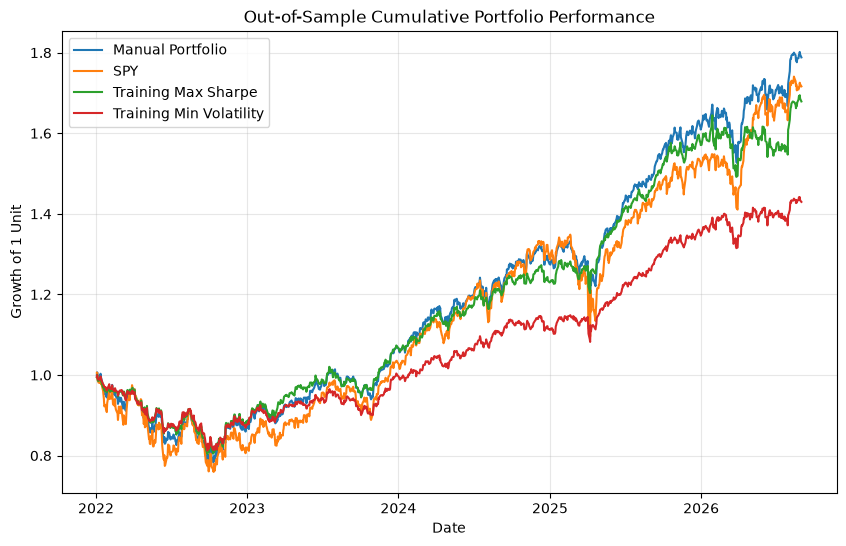

In [45]:
test_cumulative = pd.DataFrame({
    "Manual Portfolio": (1 + test_manual_returns).cumprod(),
    "SPY": (1 + test_spy_returns).cumprod(),
    "Training Max Sharpe": (1 + test_max_sharpe_returns).cumprod(),
    "Training Min Volatility": (1 + test_min_volatility_returns).cumprod()
})

fig, ax = plt.subplots(figsize=(10, 6))

for column in test_cumulative.columns:
    ax.plot(
        test_cumulative.index,
        test_cumulative[column],
        label=column
    )

ax.set_title("Out-of-Sample Cumulative Portfolio Performance")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of 1 Unit")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "out_of_sample_performance.png", dpi=200, bbox_inches="tight")
plt.show()

## Results and Interpretation

The manually constructed portfolio performed favourably relative to SPY over the full historical period. It achieved a CAGR of approximately 15.4%, compared with 15.2% for SPY, while experiencing substantially lower annualised volatility (13.3% versus 17.8%) and a smaller maximum drawdown (-23.3% versus -33.7%). This resulted in a higher historical Sharpe ratio of 0.98 compared with 0.76 for SPY.

The in-sample Monte Carlo analysis identified portfolios with stronger historical risk-return characteristics. In particular, the maximum-Sharpe portfolio achieved a Sharpe ratio of approximately 1.25. However, this portfolio was selected and evaluated using the same historical data, meaning its performance is likely to overstate how well the allocation would perform on unseen data.

The out-of-sample analysis provides a more realistic test. Using only 2016–2021 data to select portfolio weights, the maximum-Sharpe allocation achieved a Sharpe ratio of approximately 0.75 during 2022–2026, compared with 0.73 for the manual portfolio and 0.53 for SPY. Its CAGR of 11.8% was nevertheless below the manual portfolio's 13.3%.

Overall, the results suggest that diversification across equities, government bonds and gold reduced portfolio risk over the period analysed. They also demonstrate that an allocation optimised using historical data does not necessarily maximise future returns, and that evaluating an optimisation method outside its training period is important when assessing its effectiveness.

## Limitations

Several limitations should be considered when interpreting the results:

- Historical returns, volatilities and correlations may not be representative of future market conditions.
- Expected returns are estimated using historical arithmetic mean returns, which can be unstable and sensitive to the selected time period.
- Correlations and covariances are assumed to be sufficiently stable for portfolio construction, although these relationships can change significantly during periods of market stress.
- The Monte Carlo simulation considers 10,000 randomly generated long-only portfolios and therefore does not guarantee identification of the mathematically optimal allocation.
- The analysis assumes constant portfolio weights, effectively requiring frequent rebalancing. Transaction costs, taxes, bid-ask spreads and other implementation costs are not included.
- The selected asset universe is limited and contains overlapping exposures. In particular, SPY already contains MSFT, JPM and CAT, meaning their inclusion as individual holdings represents deliberate additional exposure to those companies.
- The asset universe itself was selected using current knowledge, creating potential selection and survivorship bias.
- The risk-free rate is approximated using the 3-month US Treasury bill rate.
- The full-period optimisation is evaluated in-sample and is therefore susceptible to overfitting. The separate 2016–2021 training and 2022–2026 testing periods reduce this problem, but a single out-of-sample period is still insufficient to establish that the strategy will generalise across different market environments.